# Генерации RealNVP: CelebA и CIFAR-10

Веса положить в корень репозитория (рядом с `src/`): `realnvp_weights_celeba_1.pt`, `realnvp_weights_cifar10_1.pt`.
Модели обучены с `hidden_channels=128`, остальные параметры `RealNVP` по умолчанию.
Для отбора CelebA по FID нужен кэш реальных картинок `data/celeba64_valid.pt` (собирается `load_celeba`).

In [1]:
import sys
from pathlib import Path

import torch

sys.path.append("../src")
from flows import InceptionFeatures, RealNVP, load_celeba, to_float
from flows.plotting import show_best_n_samples, show_images, use_style

HIDDEN_CHANNELS = 128
N_BLOCKS = 2
N_SAMPLES = 20
TEMPERATURES = [0.9, 0.8]
N_CANDIDATES = 500
N_REAL = 2000

WEIGHTS_DIR = Path("..")
DATA_ROOT = Path("../data")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

use_style()
print(f"PyTorch {torch.__version__} | {DEVICE}")


def load_model(weights, height, width):
    model = RealNVP(3, height, width, hidden_channels=HIDDEN_CHANNELS, n_blocks=N_BLOCKS).to(DEVICE)
    model.load_state_dict(torch.load(weights, map_location=DEVICE, weights_only=True))
    return model.eval()


celeba_model = load_model(WEIGHTS_DIR / "realnvp_weights_celeba_1.pt", 64, 64)
cifar_model = load_model(WEIGHTS_DIR / "realnvp_weights_cifar10_1.pt", 32, 32)
inception = InceptionFeatures(DEVICE)

PyTorch 2.14.1+cpu | cpu


## CelebA 64×64

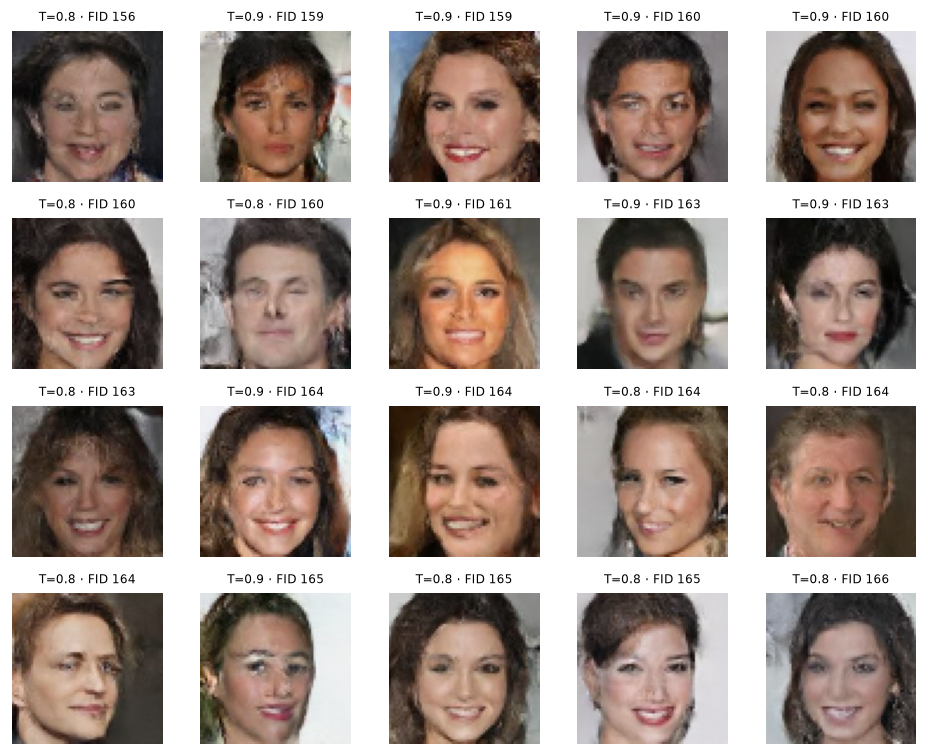

In [2]:
celeba_stats = inception.stats(to_float(load_celeba(DATA_ROOT, "valid")[:N_REAL]))
show_best_n_samples(celeba_model, N_SAMPLES, inception, celeba_stats, TEMPERATURES, N_CANDIDATES)

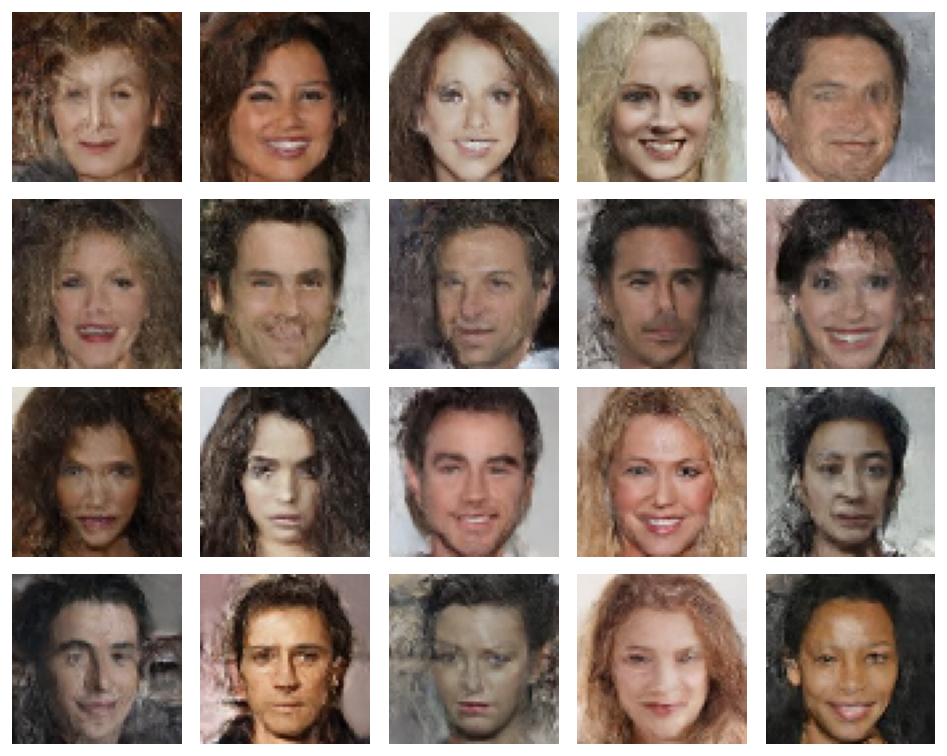

In [13]:
show_images(celeba_model.sample(N_SAMPLES, temperature=0.75))

## CIFAR-10 32×32

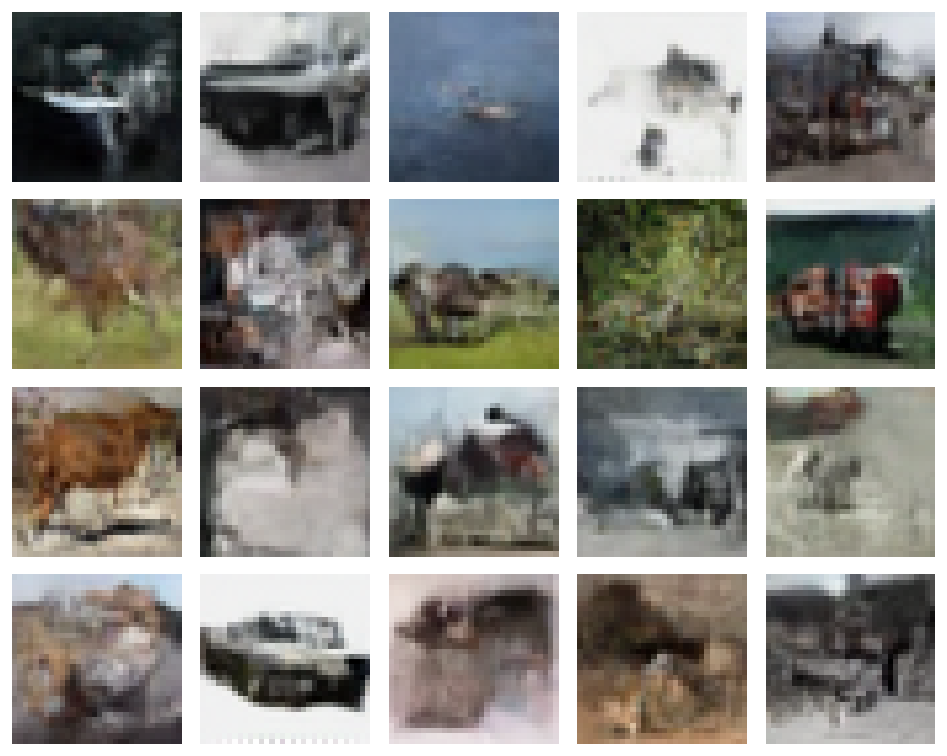

In [14]:
show_images(cifar_model.sample(N_SAMPLES, temperature=0.9))